# 01 小程序 - 起步


本篇是微信小程序基础第 1 天，依据《小程序 - 起步》原讲义与 `mp_01` 配套代码整理。学习顺序是：小程序简介 → 创建第一个小程序 → 代码的构成 → 宿主环境与常用组件 → 协同工作和发布。

资料来自[课程网盘](https://pan.baidu.com/s/1crZTQdIZ7OSDkZIpIWkhYw?pwd=1234)中“微信小程序基础”的 `day01.rar`。本地压缩包位于 `D:\baidudisk\BaiduNetdiskDownload\day01.rar`，内含 85 页正文 PDF、4 页目标 PDF、PPT、学习目标、代码和资料。配套 `资料.rar` 中有练习图片 `1.png` 以及旧版微信开发者工具的 32 位、64 位安装包；本篇按讲义建议使用官方最新稳定版工具。

| 配套位置 | 用途 |
| --- | --- |
| `代码/mp_01/app.json` | 注册页面、设置窗口、调整首页 |
| `代码/mp_01/pages/index` | 默认示例页与单页窗口配置 |
| `代码/mp_01/pages/list` | 本课常用组件练习 |
| `代码/mp_01/images/1.png` | `image` 组件练习图片 |
| `代码/mp_01/pages/logs`、`utils/util.js` | 默认日志页与时间格式化模块 |

课程资料形成于 2020 年，配套基础库版本为 `2.11.1`。下面保留原课的配置和步骤；当前工具界面与用户信息能力可能有所变化，在相关位置说明。代码只用于阅读，不使用执行单元，也没有在本机执行注册、上传、审核或发布操作。


## 一、小程序简介

### 1. 小程序与普通网页开发的区别

小程序的结构、样式与逻辑仍然分工明确，但运行环境和开发入口与网页不同。

| 比较项 | 普通网页 | 微信小程序 |
| --- | --- | --- |
| 运行环境 | 浏览器 | 微信环境 |
| API | 浏览器提供 DOM、BOM 等 API | 小程序不能直接调用 DOM、BOM API；使用微信环境提供的能力，例如定位、扫码、支付 |
| 开发模式 | 浏览器 + 代码编辑器 | 申请开发账号 → 安装微信开发者工具 → 创建和配置小程序项目 |

DOM 是对网页文档节点的操作接口；BOM 是浏览器窗口等对象的接口。不能把网页里的 `document`、`window` 操作直接搬进小程序。

### 2. 先体验一个小程序

原讲义给出小程序码，使用手机微信扫码进入示例，观察它的页面与操作方式。课件要求微信 `6.7.2` 及以上，这是课程当时的体验条件。体验用于认识运行形式，后面再创建自己的项目。


## 二、第一个小程序

先取得小程序 AppID，再准备微信开发者工具，最后创建项目并预览。AppID 是平台分配给小程序的标识，创建项目时要填写自己账号的 AppID。


### 1. 注册小程序开发账号并取得 AppID

在[微信公众平台](https://mp.weixin.qq.com/)操作，原课的完整顺序如下：

1. 点击右上角“立即注册”。
2. 账号类型选择“小程序”。
3. 填写邮箱、密码、确认密码及页面要求的信息。课件提示每个邮箱只能申请一个小程序，并需要使用符合页面要求的未注册邮箱。
4. 页面提示邮箱激活后，打开对应邮箱。
5. 点击激活邮件中的链接。
6. 选择注册国家或地区及主体类型；讲义以“中国大陆 → 个人”为例。
7. 完成主体信息登记。个人示例填写姓名、身份证号、管理员手机号和短信验证码，并使用管理员本人微信进行身份验证。
8. 注册完成后，登录小程序管理后台，进入“开发 → 开发设置”，在“开发者 ID”区域取得 `AppID（小程序 ID）`。

主体类型要与实际身份一致，个人主体与企业主体的能力存在差别。课件当时提示个人主体不支持微信认证、微信支付和部分高级接口；实际注册条件以当前平台页面为准。

完成后应能在后台看到自己的 AppID。配套项目里的 `appid` 是讲师示例值，导入练习项目时替换为自己的值，不把示例 AppID 当作个人账号使用。


### 2. 安装并登录微信开发者工具

微信开发者工具负责创建项目、查看和编辑代码、调试功能、预览以及上传代码。

1. 打开[官方稳定版下载页](https://developers.weixin.qq.com/miniprogram/dev/devtools/stable.html)，选择适合操作系统的 Stable Build。
2. 启动安装程序，按向导完成安装并点击“完成”。
3. 打开工具，用微信扫码，再在手机上确认登录。
4. 首次进入后，可以在设置里调整外观。原课使用浅色主题、Consolas 字体、字号 `18`、行距 `1.2`，并把模拟器放在左侧。
5. 原课在“代理”中选“不使用任何代理，勾选后直连网络”；这是课堂网络环境的设置，实际使用时按自己的网络环境选择。

配套 `资料.rar` 的安装包为 `wechat_devtools_1.02_ia32.exe` 和 `wechat_devtools_1.02_x64.exe`，用于对应课程当时的界面。完成登录后应进入项目列表，能够新建或导入小程序。


### 3. 创建 `mp_01` 项目

在微信开发者工具的“小程序”项目列表点击“加号”，进入“新建项目”。按原课填写：

| 字段 | 课堂选择 |
| --- | --- |
| 项目名称 | `mp_01` |
| 目录 | 选择本机用于保存项目的文件夹；课件示例为 `E:\mp_01` |
| AppID | 上一步取得的自己的 AppID |
| 开发模式 | 小程序 |
| 后端服务 | 不使用云服务 |
| 语言 | JavaScript |

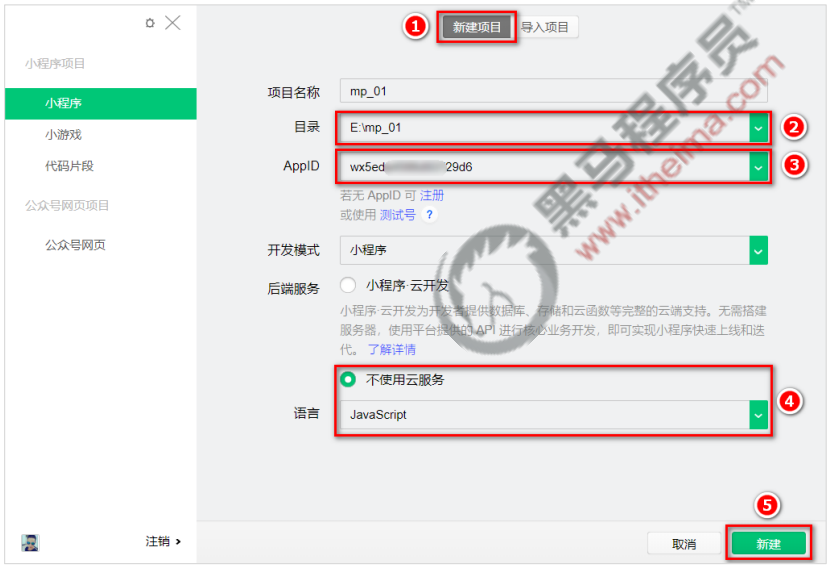

点击“新建”后，工具创建基础项目并进入编辑主界面。当前稳定版界面可能改为通过模板选择创建方式，按照本课的 JavaScript 小程序和不使用云服务的条件选择。

如果直接查看配套代码，使用“导入项目”，目录指向 `mp_01` 根目录，即能看到 `app.json` 的那一层。新建默认项目与导入本课完成版的首屏不同：默认项目是 `index` 页，完成版把 `list` 页排在第一位。


### 4. 在模拟器与真机上预览

**模拟器：**项目创建完成后，点击工具栏的“编译”，左侧模拟器显示首页。原课默认模板包含“获取头像昵称”和 `Hello World`；本课后续会把首页换成组件练习页。

**真机：**点击工具栏“预览”，工具生成预览二维码，用手机微信扫码打开。真机预览用于检查手机中的实际展示和操作。

配套默认模板包含 `open-type="getUserInfo"`、`wx.getUserInfo()` 等旧版用户信息逻辑。它们是本课当时的模板内容，当前平台的头像昵称获取规则已有变化；不能把旧截图中的授权结果当作当前运行保证。本课此处重点是创建、编译和预览项目。

验证时先确认能完成编译、模拟器中能显示页面，再检查手机预览。发生配置或模板错误时，从调试区读取错误对应的文件和位置。


### 5. 认识主界面的五个部分

| 区域 | 用途 |
| --- | --- |
| 菜单栏 | 项目、文件、编辑、设置等入口 |
| 工具栏 | 编译、预览、真机调试、上传等操作 |
| 模拟器 | 查看页面显示与交互 |
| 代码编辑区 | 浏览项目目录并编辑文件 |
| 调试区 | 查看日志、错误与调试信息 |

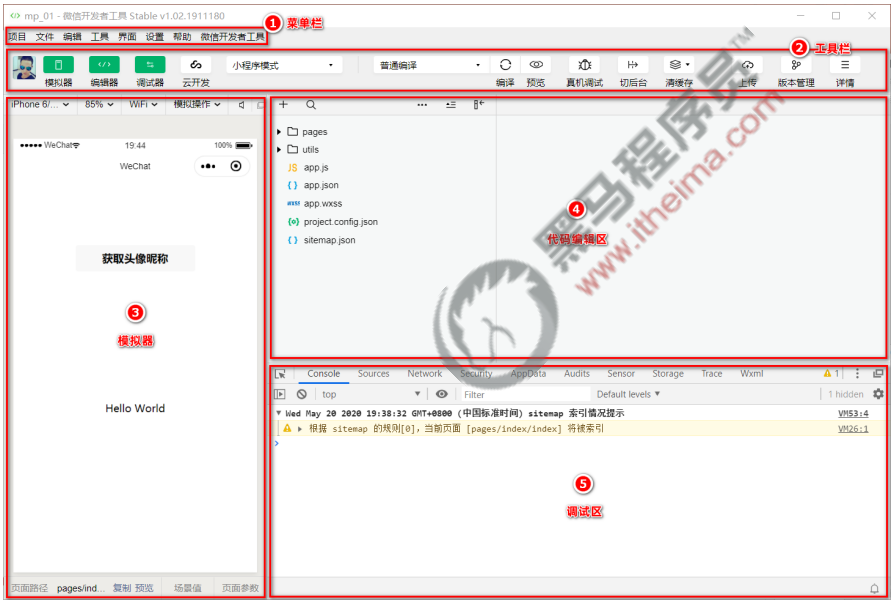

接下来的练习在代码编辑区修改文件，保存后编译，在模拟器中观察变化；需要排查时查看调试区。


## 三、小程序代码的构成

小程序项目有全局文件，也有各页面自己的文件。先分清文件的作用，再决定修改位置。


### 1. 项目的基本组成结构

以配套 `mp_01` 为例：

```text
mp_01/
├── pages/
│   ├── index/
│   ├── list/
│   └── logs/
├── utils/
│   └── util.js
├── images/
│   └── 1.png
├── app.js
├── app.json
├── app.wxss
├── project.config.json
└── sitemap.json
```

| 位置 | 作用 |
| --- | --- |
| `pages` | 存放小程序页面，每个页面放在单独的文件夹中 |
| `utils` | 存放工具模块，例如时间格式化函数 |
| `app.js` | 整个小程序的入口文件 |
| `app.json` | 全局配置文件 |
| `app.wxss` | 全局样式文件 |
| `project.config.json` | 项目和开发工具配置 |
| `sitemap.json` | 配置页面是否允许微信索引 |
| `images` | 配套代码存放练习图片的目录 |

### 2. 一个页面的四个基本文件

例如 `pages/list` 中的文件共用 `list` 这个名称：

| 文件 | 内容 |
| --- | --- |
| `list.js` | 页面数据、事件处理函数等逻辑 |
| `list.json` | 当前页面的配置，例如窗口外观 |
| `list.wxml` | 页面结构 |
| `list.wxss` | 当前页面的样式 |

`.wxml` 决定页面有哪些组件，`.wxss` 决定组件的样式，`.js` 处理数据和操作，`.json` 配置页面表现。


### 3. 四种 JSON 配置文件

JSON 是数据格式，本课用 `.json` 文件配置不同范围的行为。四种配置分别为：根目录 `app.json`、根目录 `project.config.json`、根目录 `sitemap.json` 和每个页面的 `.json`。

#### `app.json`：全局配置

配套完成版的完整内容是：

```json
{
  "pages": [
    "pages/list/list",
    "pages/index/index",
    "pages/logs/logs"
  ],
  "window": {
    "backgroundTextStyle": "light",
    "navigationBarBackgroundColor": "#fff",
    "navigationBarTitleText": "WeChat",
    "navigationBarTextStyle": "black"
  },
  "style": "v2",
  "sitemapLocation": "sitemap.json"
}
```

| 字段 | 本课作用 |
| --- | --- |
| `pages` | 记录页面路径，不写文件扩展名 |
| `window` | 全局窗口配置，影响导航栏、背景等 |
| `style` | 指定组件样式版本，本课为 `v2` |
| `sitemapLocation` | 指向索引配置文件，本课为 `sitemap.json` |

`backgroundTextStyle: "light"` 是背景区域的文本样式设置；`navigationBarBackgroundColor` 为导航栏背景色，`navigationBarTitleText` 为导航栏标题，`navigationBarTextStyle` 为导航栏文字样式。

`app.json` 还可配置底部 tab 等全局表现，本课只认识这些位置，不展开后续课程的 tabBar 配置。


#### `project.config.json`：项目与工具配置

配套文件中的关键字段如下，省略其他配置；合并时保留现有文件的其他内容：

```json
{
  "setting": {
    "es6": true,
    "checkSiteMap": false
  },
  "compileType": "miniprogram",
  "libVersion": "2.11.1",
  "appid": "wx5eda4566d93729d6",
  "projectname": "mp_01"
}
```

`setting` 保存编译等设置；`projectname` 是项目名称；`appid` 是小程序账号 ID。上面的 AppID 是资料原值，练习时替换为自己的值。`libVersion: "2.11.1"` 用来识别本课基础库环境。

#### `sitemap.json`：微信索引配置

微信可以为允许索引的页面内容建立索引，当用户搜索关键词与索引匹配时，页面可能出现在搜索结果中。配套完成版使用下面的规则：

```json
{
  "desc": "关于本文件的更多信息，请参考文档 https://developers.weixin.qq.com/miniprogram/dev/framework/sitemap.html",
  "rules": [{
  "action": "disallow",
  "page": "*"
  }]
}
```

`action: "disallow"` 配合 `page: "*"`，表示不允许索引所有页面。讲义说明索引提示默认开启，配套 `project.config.json` 在 `setting` 中设置 `checkSiteMap: false` 关闭提示。

> `sitemap.json` 的规则决定页面是否允许索引；`checkSiteMap` 决定开发工具是否显示索引提示。这两个设置各有作用。


#### 页面 `.json`：覆盖本页窗口配置

`pages/index/index.json` 的内容为：

```json
{
  "usingComponents": {},
  "navigationBarBackgroundColor": "#00b26a"
}
```

`navigationBarBackgroundColor: "#00b26a"` 覆盖了全局 `window` 中的 `"#fff"`。页面配置项直接写在该页面 JSON 根级，不再套一个 `window`。

验证时打开 `index` 页，它的导航栏背景使用单页配置；没有设置相同字段的页面继续使用全局值。

### 4. 新建页面

在 `app.json` 的 `pages` 数组中追加路径：

```json
{
  "pages": [
    "pages/index/index",
    "pages/logs/logs",
    "pages/list/list"
  ]
}
```

这是课堂添加 `list` 页时的字段片段。保存后，微信开发者工具会帮助创建 `pages/list` 下的 `.js`、`.json`、`.wxml`、`.wxss` 四个文件。检查路径的目录名、文件名与生成文件是否一致。

### 5. 修改项目首页

把 `pages/list/list` 移到数组的第一位，再按普通启动方式编译，首页就是 `list` 页。配套完成版的 `app.json` 已按这个顺序排列。

> 本课通过 `pages` 的第一项确定默认首页。如果开发工具选择了自定义编译条件，先切回普通编译，再验证这个变化。


### 6. WXML：页面结构

WXML（WeiXin Markup Language）是小程序框架的标签语言，用来构建页面结构，作用类似 HTML。两者的主要区别如下：

| 网页中的标签或写法 | 小程序中的标签或写法 |
| --- | --- |
| `div` | `view`，用于布局 |
| `span` | `text`，用于文本 |
| `img` | `image`，用于图片 |
| `a` 的 `href` | `navigator` 的 `url`，用于页面导航 |

例如本项目已经有 `list` 页面，可以使用：

```xml
<navigator url="/pages/list/list">打开列表页</navigator>
```

原讲义用 `/pages/home/home` 演示 `url` 属性；配套 `mp_01` 没有 `home` 页，上面换成已注册的 `list` 路径，只为说明标签和属性的对应关系。

WXML 还提供类似 Vue 的数据绑定、列表渲染、条件渲染。配套默认页用 `{{motto}}` 显示页面数据，用 `wx:if` 判断是否显示按钮；这些模板语法在第 02 天继续讲解。


### 7. WXSS：页面样式

WXSS（WeiXin Style Sheets）描述 WXML 组件的样式，作用类似 CSS。原课强调三点：

1. **新增 `rpx` 尺寸单位。**不同大小的屏幕上由小程序进行换算，本课先知道它用于适配。
2. **有全局样式和局部样式。**根目录 `app.wxss` 作用于所有页面；页面 `.wxss` 作用于当前页面。
3. **支持的选择器有范围。**本课列出 `.class`、`#id`、元素选择器、并集选择器、后代选择器，以及 `::after`、`::before`。后两者按规范属于伪元素，讲义在这里统一称为“伪类选择器”。

例如配套 `app.wxss` 的全局 `.container` 使用了 Flex 布局与 `rpx`：

```css
/**app.wxss**/
.container {
  height: 100%;
  display: flex;
  flex-direction: column;
  align-items: center;
  justify-content: space-between;
  padding: 200rpx 0;
  box-sizing: border-box;
}
```

本课组件练习使用 `.container1`，与默认模板中的 `.container` 区分。不要直接给练习区套上 `.container`，否则会同时受到这组全局布局和内边距的影响。


### 8. JS：逻辑与交互

页面既要显示内容，也要响应点击、获取数据等操作。小程序里的 JavaScript 文件分为三类：

| 类型 | 入口或用途 |
| --- | --- |
| `app.js` | 调用 `App()`，注册整个小程序实例 |
| 页面 `.js` | 调用 `Page()`，注册页面实例 |
| 普通 `.js` 模块 | 封装公共函数或属性，供页面引用 |

配套 `pages/index/index.js` 的页面数据包含 `motto: 'Hello World'`，`index.wxml` 通过 `{{motto}}` 使用它；配套 `app.js` 通过 `App()` 注册入口。

普通模块的实际例子是 `utils/util.js`，其中导出 `formatTime`。默认日志页的脚本完整如下：

```javascript
//logs.js
const util = require('../../utils/util.js')

Page({
  data: {
    logs: []
  },
  onLoad: function () {
    this.setData({
      logs: (wx.getStorageSync('logs') || []).map(log => {
        return util.formatTime(new Date(log))
      })
    })
  }
})
```

这段代码用 `require('../../utils/util.js')` 引用工具模块，在 `onLoad` 中读取日志并调用格式化函数，再通过 `setData` 更新页面数据。本课先分清各类 JS 文件的职责，生命周期与数据更新的细节留在相应课程。


## 四、小程序的宿主环境

宿主环境指程序运行所依赖的环境。本课从宿主、通信模型和运行机制讲起，再学习微信提供的组件与 API。


### 1. 手机微信是小程序的宿主环境

Android 软件运行在 Android 系统中，iOS 软件运行在 iOS 系统中；小程序则运行在微信提供的环境里。

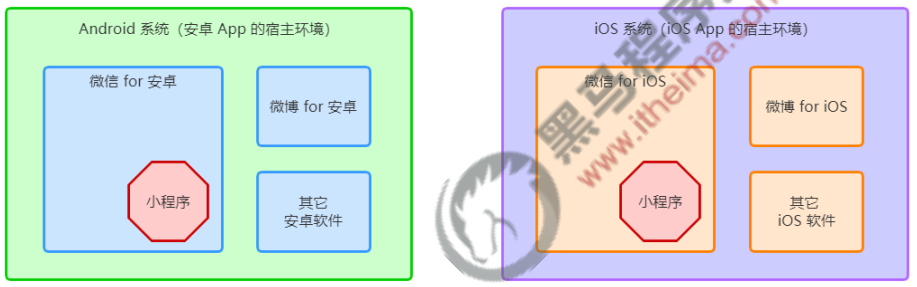

小程序借助微信提供的能力使用扫码、支付、登录、定位等功能。宿主环境的内容包括通信模型、运行机制、组件和 API。


### 2. 渲染层、逻辑层与通信模型

| 主体 | 工作内容 |
| --- | --- |
| 渲染层 | WXML 模板和 WXSS 样式，负责页面展示 |
| 逻辑层 | JS 脚本，负责逻辑处理 |

原课把通信分为两部分：渲染层与逻辑层之间的通信，逻辑层与第三方服务器之间的通信。这两类通信由微信客户端转发。

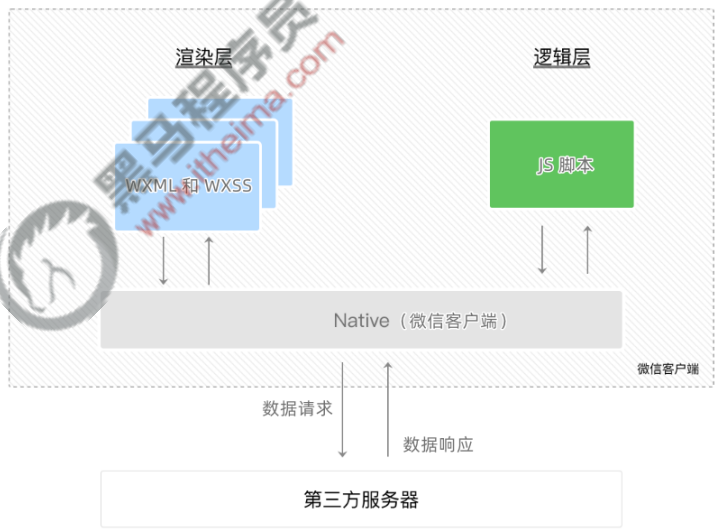

因此，页面展示和 JS 逻辑属于不同的工作层；访问服务器也通过宿主提供的能力完成。


### 3. 小程序启动与页面渲染的过程

**启动小程序：**

1. 将小程序代码包下载到本地。
2. 解析 `app.json` 全局配置。
3. 执行 `app.js`，调用 `App()` 创建小程序实例。
4. 渲染小程序首页。
5. 小程序启动完成。

**渲染页面：**

1. 加载、解析页面的 `.json` 配置。
2. 加载页面的 `.wxml` 模板和 `.wxss` 样式。
3. 执行页面 `.js`，调用 `Page()` 创建页面实例。
4. 页面渲染完成。

这两个过程对应前面认识的全局文件和页面四个文件。排查首页路径、窗口样式或页面内容问题时，先确认负责该内容的文件。


### 4. 组件的分类与练习位置

组件是微信宿主环境提供的界面构件，原课按九类介绍：视图容器、基础内容、表单组件、导航组件、媒体组件、`map` 地图组件、`canvas` 画布组件、开放能力、无障碍访问。

本课使用的视图容器包括：

| 组件 | 用途 |
| --- | --- |
| `view` | 普通视图区域，类似 `div`，常用于布局 |
| `scroll-view` | 可滚动视图区域，常用于滚动列表 |
| `swiper` | 轮播容器 |
| `swiper-item` | 轮播容器内的一项 |

下面的组件示例放在 `pages/list/list.wxml`，对应样式放在 `pages/list/list.wxss`，不修改全局 `app.wxss`。建议按顺序逐个替换练习。

配套完成版把 `scroll-view`、轮播、文本和按钮等阶段示例注释起来，最终只保留图片展示。笔记展开这些阶段代码以便阅读，原始配套文件保持原样；练习时取消所需片段的注释，避免把所有示例同时开启造成布局干扰。


### 5. `view`：实现 Flex 横向布局

先用普通 `view` 容器放三个子区域，让 A、B、C 横向排列。

`pages/list/list.wxml`：

```xml
<view class="container1">
  <view>A</view>
  <view>B</view>
  <view>C</view>
</view>
```

`pages/list/list.wxss`，依据讲义第 54 页代码整理：

```css
.container1 view {
  width: 100px;
  height: 100px;
  text-align: center;
  line-height: 100px;
}

.container1 view:nth-child(1) {
  background-color: lightgreen;
}

.container1 view:nth-child(2) {
  background-color: lightskyblue;
}

.container1 view:nth-child(3) {
  background-color: lightcoral;
}

.container1 {
  display: flex;
  justify-content: space-around;
}
```

父容器的 `display: flex` 让三个子区域横向排列，`justify-content: space-around` 分配横向空白。子区域的 `line-height` 与高度相等，让单行字母垂直居中。

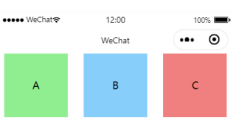

保存并编译后，三个 `100px × 100px` 的色块应横向排开。配套源码后来改成了滚动示例，因此这一步的第三块颜色沿用讲义的 `lightcoral`。


### 6. `scroll-view`：实现纵向滚动

把父容器换成 `scroll-view`，开启 `scroll-y`，同时限制容器高度。子区域总高度超过容器，才会产生内部滚动。

`pages/list/list.wxml`，展开配套源码中的注释片段：

```xml
<scroll-view class="container1" scroll-y>
  <view>A</view>
  <view>B</view>
  <view>C</view>
</scroll-view>
```

`pages/list/list.wxss`，使用本阶段样式替换上一阶段的布局样式：

```css
.container1 view {
  width: 100px;
  height: 100px;
  text-align: center;
  line-height: 100px;
}

.container1 view:nth-child(1) {
  background-color: lightgreen;
}
.container1 view:nth-child(2) {
  background-color: lightskyblue;
}
.container1 view:nth-child(3) {
  background-color: lightpink;
}

.container1 {
  border: 1px solid red;
  width: 100px;
  height: 120px;
}
```

每个子区域高 `100px`，三个共 `300px`，外层高 `120px`；编译后应看到红色边框中的局部内容，并可纵向滚动查看 B、C。

> `scroll-y` 允许纵向滚动，`scroll-x` 允许横向滚动。原课特别强调：使用竖向滚动时，必须给 `scroll-view` 固定高度。保留上一节父容器的横向 Flex 布局会改变这个示例的效果。


### 7. `swiper` 与 `swiper-item`：轮播

外层 `swiper` 控制切换行为，每一个 `swiper-item` 放一页内容。配套源码使用 A、B、C 色块演示，虽然本节称“轮播图”，也可以轮播普通内容。

`pages/list/list.wxml`，展开配套源码：

```xml
<swiper class="swiper-container" indicator-dots indicator-color="white" indicator-active-color="gray" autoplay interval="3000" circular>
	<swiper-item>
    <view class="item">A</view>
  </swiper-item>
	<swiper-item>
    <view class="item">B</view>
  </swiper-item>
	<swiper-item>
    <view class="item">C</view>
  </swiper-item>
</swiper>
```

`pages/list/list.wxss`：

```css
.swiper-container {
  height: 150px;
}

.item {
  height: 100%;
  line-height: 150px;
  text-align: center;
}

swiper-item:nth-child(1) .item {
  background-color: lightgreen;
}
swiper-item:nth-child(2) .item {
  background-color: lightskyblue;
}
swiper-item:nth-child(3) .item {
  background-color: lightpink;
}
```

外层高 `150px`，`.item` 的高度为父项的 `100%`。编译后应能左右切换 A、B、C；当前配置每 `3000ms` 自动切换，并能循环衔接。

讲义先使用 `indicator-dots` 显示指示点，再介绍其他属性；上面的完成版已经把常用属性合并到 `swiper`。讲义截图的第三项文字写成 B，配套源码为 C，这里按配套源码保留 C。


#### `swiper` 的常用属性

| 属性 | 类型 | 课程列出的默认值 | 作用 |
| --- | --- | --- | --- |
| `indicator-dots` | boolean | `false` | 是否显示面板指示点 |
| `indicator-color` | color | `rgba(0, 0, 0, .3)` | 未选中指示点颜色 |
| `indicator-active-color` | color | `#000000` | 当前选中指示点颜色 |
| `autoplay` | boolean | `false` | 是否自动切换 |
| `interval` | number | `5000` | 自动切换间隔，单位毫秒 |
| `circular` | boolean | `false` | 是否采用衔接滑动 |

例如本课 `indicator-color="white"` 与 `indicator-active-color="gray"` 区分指示点状态；`interval="3000"` 把默认的 5 秒改成 3 秒。

直接写布尔属性名代表启用，例如 `autoplay`。需要明确关闭时，使用布尔值绑定，例如 `autoplay="{{false}}"`，避免把字符串 `"false"` 当作布尔值。这个说明用于读懂本课属性，具体数据绑定在第 02 天展开。


### 8. `text` 与 `rich-text`：基础内容

`text` 是文本组件，类似 HTML 的 `span`；`rich-text` 是富文本组件，能够根据 `nodes` 中的 HTML 字符串渲染对应内容。

`pages/list/list.wxml` 的配套示例展开如下：

```xml
<view>
  手机号支持长按选中效果
  <text selectable>13800005056</text>
</view>

<rich-text nodes="<h1 style='color: red;'>标题</h1>"></rich-text>
```

`selectable` 让课程示例中的电话号码支持长按选中。编译后在手机中长按文本，检查选中效果。

`nodes` 的外层属性使用双引号，内层 `style` 使用单引号，保留这层引号关系。富文本应显示一个红色“标题”。这里讲的是富文本渲染，不是把网页的全部 DOM、BOM 功能引入小程序。


### 9. `button`：类型、尺寸与镂空效果

按钮可用于普通点击，也能通过 `open-type` 调用微信提供的开放能力。原课举出客服、转发、用户授权、用户信息等用途；本节实际演示按钮的外观属性。

在 `pages/list/list.wxml` 按三组观察：

```xml
<button>普通按钮</button>
<button type="primary">主色调按钮</button>
<button type="warn">警告按钮</button>
```

`type` 控制颜色类型：不指定时使用默认类型，`primary` 为主色调，`warn` 为警告类型。

```xml
<button size="mini">普通按钮</button>
<button type="primary" size="mini">主色调按钮</button>
<button type="warn" size="mini">警告按钮</button>
```

`size="mini"` 将按钮切换为小尺寸。

```xml
<button size="mini" plain>普通按钮</button>
<button type="primary" size="mini" plain>主色调按钮</button>
<button type="warn" size="mini" plain>警告按钮</button>
```

`plain` 让按钮变为镂空样式。编译后对比普通按钮、小尺寸按钮、镂空按钮，观察 `type`、`size`、`plain` 分别改变的部分。

`open-type` 的能力受当前平台规则约束；本课默认模板使用的旧版头像昵称获取方式已在前面的预览部分说明，不在这里扩展实现。


### 10. `image`：图片与裁剪、缩放模式

`image` 的默认宽度约 `300px`，高度约 `240px`。先观察默认占位区域，再加载图片。

练习图片放在项目根目录 `images/1.png`。配套 `pages/list/list.wxml` 最终启用的代码是：

```xml
<image></image>
<image src="/images/1.png" mode="heightFix"></image>
```

`pages/list/list.wxss`：

```css
image {
  border: 1px solid red;
}
```

第一张没有设置 `src`，可通过边框看到默认区域；第二张加载本地图片。`/images/1.png` 从项目根目录查找，不是相对于 `pages/list` 查找。

| `mode` 值 | 作用 |
| --- | --- |
| `scaleToFill` | 默认值，不保持纵横比，将图片拉伸到填满组件 |
| `aspectFit` | 保持纵横比，让整张图片完整显示；组件里可能留白 |
| `aspectFill` | 保持纵横比，覆盖组件显示区域；可能裁掉水平或垂直方向的部分 |
| `widthFix` | 宽度保持，高度自动变化，保留原图比例 |
| `heightFix` | 高度保持，宽度自动变化，保留原图比例 |

依次替换 `mode` 并编译，比较拉伸、完整显示、裁剪和单方向自适应的区别。配套最终代码使用 `heightFix`；讲义第 63 页截图演示的是 `aspectFit`，两者是本节不同模式的练习。


### 11. `navigator` 与三类 API

`navigator` 是页面导航组件，类似网页中的链接。本课先认识标签，第 03 天再展开页面导航方式。

API 是宿主环境提供的调用接口，开发者通过 API 使用本地存储、网络请求、登录、支付等能力。原课分成三类：

| 类型 | 特点 | 原课例子 |
| --- | --- | --- |
| 事件监听 API | 通常以 `on` 开头，监听事件触发 | `wx.onWindowResize(callback)`，监听窗口尺寸变化 |
| 同步 API | 以 `Sync` 结尾；执行结果可由返回值直接取得，出错时抛出异常 | `wx.setStorageSync('key', 'value')`，写入本地存储 |
| 异步 API | 通过 `success`、`fail`、`complete` 等回调处理结果 | `wx.request()`，发起网络请求 |

其中，`success` 接收成功结果，`fail` 处理调用失败，`complete` 在调用结束时执行。同步 API 的说明针对这一类别，并非每个同步函数都会返回业务数据；例如 `setStorageSync` 用来写入，而 `getStorageSync` 用来读取。

配套 `app.js` 启动时对日志进行本地读写，原代码中的片段为：

```javascript
// 展示本地存储能力
var logs = wx.getStorageSync('logs') || []
logs.unshift(Date.now())
wx.setStorageSync('logs', logs)
```

它读取旧日志、将本次时间放到数组开头，再写回；上面的日志页从同一个 `logs` 键读取内容。本课只认识 API 的分类，网络请求和更完整的事件逻辑在后续课程展开。


## 五、协同工作和发布

一个项目通常由产品、设计、开发、测试等成员共同完成。小程序平台通过成员角色区分后台权限，并通过版本管理组织体验、审核与上线。


### 1. 团队的组织结构与开发流程

项目管理者统筹进展和风险，安排小程序对外发布的节奏。产品组提出需求，设计组给出设计方案，开发组编写代码，测试组进行项目测试。

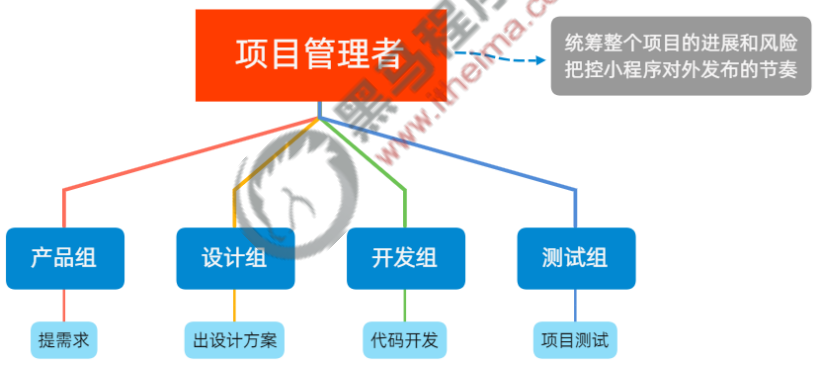

原课开发流程为：提出需求 → 设计 → 开发 → 体验 → 测试 → 发布。其中体验阶段由产品与设计参与，测试阶段由测试组完成，最后由管理者安排发布。

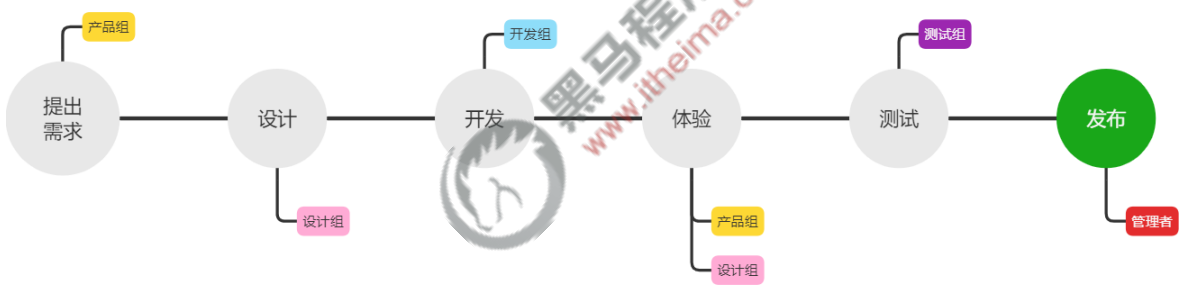

成员权限的作用是让各岗位能够完成自己的工作，同时明确操作范围。


### 2. 项目成员与体验成员

| 成员类型 | 参与内容 | 原课管理方式 |
| --- | --- | --- |
| 项目成员 | 参与开发、运营，可登录小程序管理后台 | 管理员添加或删除，并设置角色 |
| 体验成员 | 参与内测，使用体验版，不属于项目成员 | 管理员及项目成员可添加或删除 |

在小程序管理后台进入“管理 → 成员管理”，分别查看“项目成员”和“体验成员”的区域，通过各区域的添加入口登记对应微信，并为项目成员设置适合的角色。

设置完成后，核对项目成员的角色与权限；体验成员应能使用被设为体验版的版本。只有被赋予相应权限的人才能完成对应后台或开发操作。


### 3. 不同项目成员的权限

下表按讲义第 72 页整理，`✓` 表示原课该角色拥有此权限，`—` 表示原课表格未赋予。

| 权限 | 运营者 | 开发者 | 数据分析者 |
| --- | --- | --- | --- |
| 开发者权限 | — | ✓ | — |
| 体验者权限 | ✓ | ✓ | ✓ |
| 登录 | ✓ | ✓ | ✓ |
| 数据分析 | — | — | ✓ |
| 微信支付 | ✓ | — | — |
| 推广 | ✓ | — | — |
| 开发管理 | ✓ | — | — |
| 开发设置 | — | ✓ | — |
| 暂停服务 | ✓ | — | — |
| 解除关联公众号 | ✓ | — | — |
| 腾讯云管理 | — | ✓ | — |
| 小程序插件 | ✓ | — | — |
| 游戏运营管理 | ✓ | — | — |

原课单独说明开发者的五项权限：

1. **开发者权限：**使用微信开发者工具，对小程序进行代码开发。
2. **体验者权限：**使用体验版小程序。
3. **登录权限：**登录小程序管理后台，无需管理员确认。
4. **开发设置：**设置服务器域名、消息推送，以及扫描普通链接二维码打开小程序。
5. **腾讯云管理：**进行云开发相关设置。

这张表是课程当时的权限安排，实际角色与授权范围以当前后台展示为准。


### 4. 小程序的四种版本

代码开发期间先自测，达到可体验状态后交给产品与测试人员，修复问题后再发布正式版。平台中对应以下版本：

| 版本阶段 | 原课说明 |
| --- | --- |
| 开发版本 | 通过开发者工具上传；每位开发者保留最新的一份上传代码；可以提交审核，删除开发版本不影响线上或审核中的版本 |
| 体验版本 | 可从开发版本中选择一份设为体验版，同一时刻选取一份供内测 |
| 审核中的版本 | 同一时刻只能有一份代码处于审核中；有结果后可发布，也可重新提交覆盖原审核版本 |
| 线上版本 | 所有用户实际访问的版本，发布新版本后被更新 |

“预览”“上传开发版”“设为体验版”“发布上线”分别处于不同步骤。手机扫开发工具生成的预览二维码，不代表小程序已经发布给所有用户。


### 5. 发布上线：上传代码 → 提交审核 → 发布

下面记录原课的操作流程，作为学习内容。本次整理笔记没有执行这些平台操作。

#### 上传代码

1. 在微信开发者工具中确认项目代码和 AppID 正确。
2. 点击顶部工具栏“上传”。
3. 填写版本号和项目备注，完成上传。
4. 登录小程序管理后台，进入“管理 → 版本管理 → 开发版本”，查看刚上传的版本。

验证时核对版本号、备注和上传内容，确认后台能看到该开发版本。需要内测时，从开发版本中选择一份设为体验版，再由体验成员使用。

#### 提交审核

发布前需要腾讯官方审核，以检查小程序质量与平台规范。在“开发版本”列表点击“提交审核”，按页面要求填写相关信息，提交后查看审核中的版本及结果。

#### 发布

审核通过后，管理员微信会收到通过通知。在审核版本列表点击“发布”，将审核通过的版本变为线上版本。发布后用户才能通过线上入口访问这个版本。

> 上传代码只生成开发版本；审核通过后，还需要发布，才成为线上版本。


### 6. 获取小程序码与查看运营数据

#### 小程序码推广

相对于普通二维码，小程序码在外观上更容易识别，有助于展示品牌和推广小程序。原课取得小程序码的路径是：

登录小程序管理后台 → 设置 → 基本设置 → 基本信息 → 小程序码及线下物料下载。

下载与自己的小程序对应的码，再用于推广。课程中的二维码和小程序码属于讲师示例，不作为自己的项目入口。

#### 两种运营数据入口

| 方式 | 原课步骤 |
| --- | --- |
| 小程序后台 | 登录后台 → 点击侧边栏“统计” → 切换相应标签查看数据 |
| 小程序数据助手 | 打开微信 → 搜索“小程序数据助手” → 查看已发布的小程序数据 |

这些入口用于查看发布后的使用情况，当前后台的具体菜单名称可能随平台更新调整。


## 六、原课学习目标

原讲义与 `学习目标.txt` 给出的五项要求为：

1. 能够知道如何创建小程序项目：获取 AppID，使用微信开发者工具创建、编译与预览。
2. 能够清楚项目的基本组成结构：`app.js`、`app.json`、`app.wxss`、`pages` 等。
3. 能够知道一个页面由哪些部分组成：`.wxml`、`.wxss`、`.json`、`.js`。
4. 能够知道常见组件如何使用：`view`、`scroll-view`、`swiper`、`text`、`rich-text`、`button`、`image` 等。
5. 能够知道如何协同开发和发布：成员管理、开发与体验版本、上传、审核、发布以及查看运营数据。

按本课顺序练习时，应能把 `list` 设置为默认首页，独立切换并验证各组组件，再说清全局文件、单页文件以及各版本阶段的职责。
